# Persistence

LangGraph has a built-in persistence layer, implement through checkpointers. When compile a graph with checkpointer, it work like this: 
- Saving logic: ***checkpoint -> thread -> graph state***.
- Actual order: Graph → Thread → Run → Checkpoint → State (snapshot)

Where:
- **Checkpoint**: Acting like graph memory, being save at every super-step -> Help it understand where it's right now, what the information it kept (state)
- **Graph State**: Can be runtime memory, metadata, decision of the graph
- **Threads**: A unique ID or can be call a identifier assigned to each checkpoint. Contain the accumulated state of a sequence of runs

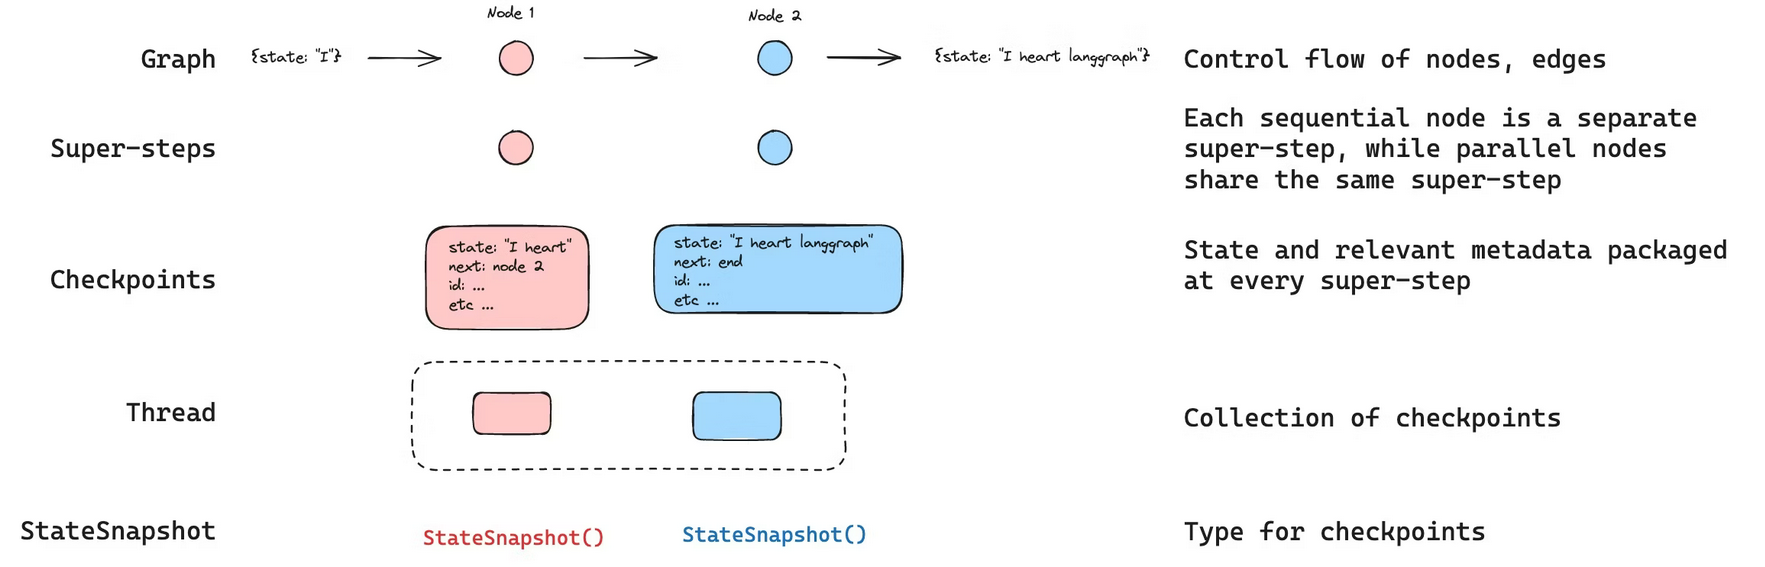

### Threads

When a run is executed, the state of the graph will be persisted to the thread -> invoke a graph with a checkpointer required a `thread_id`

The Checkpointer uses thread_id as primary key for storing and retrieving checkpoints

### Checkpoints

The state of a thread at a particular point in time is called a checkpoint. Using `StateSnapshot` object with:
- `config`
- `metadata`
- `values`: Values of the state channels at this point of time
- `next`: A tuple of the node names to execute next in graph
- `tasks`: A tuple of `PregelTask` object contain information about what next to be executed (Also handle error / cut off action)

Checkpoints are persisted and can be used to restore the state of a thread at a later time.

#### Code method

#### `graph.get_state(config)`

Use to extract latest state specify by a `thread_id`. This return a `StateSnapshot` object that corresponds to the latest checkpoint associated with the `thread_id` provided in the config or a checkpoint associated with `checkpoint_id` for the thread (if provided only)

#### `graph.get_state_history(config)`

Use to extract full history of the graph execution for a given `thread_id`. Return a list of `StateSnapshot` objects associated with the ID provided

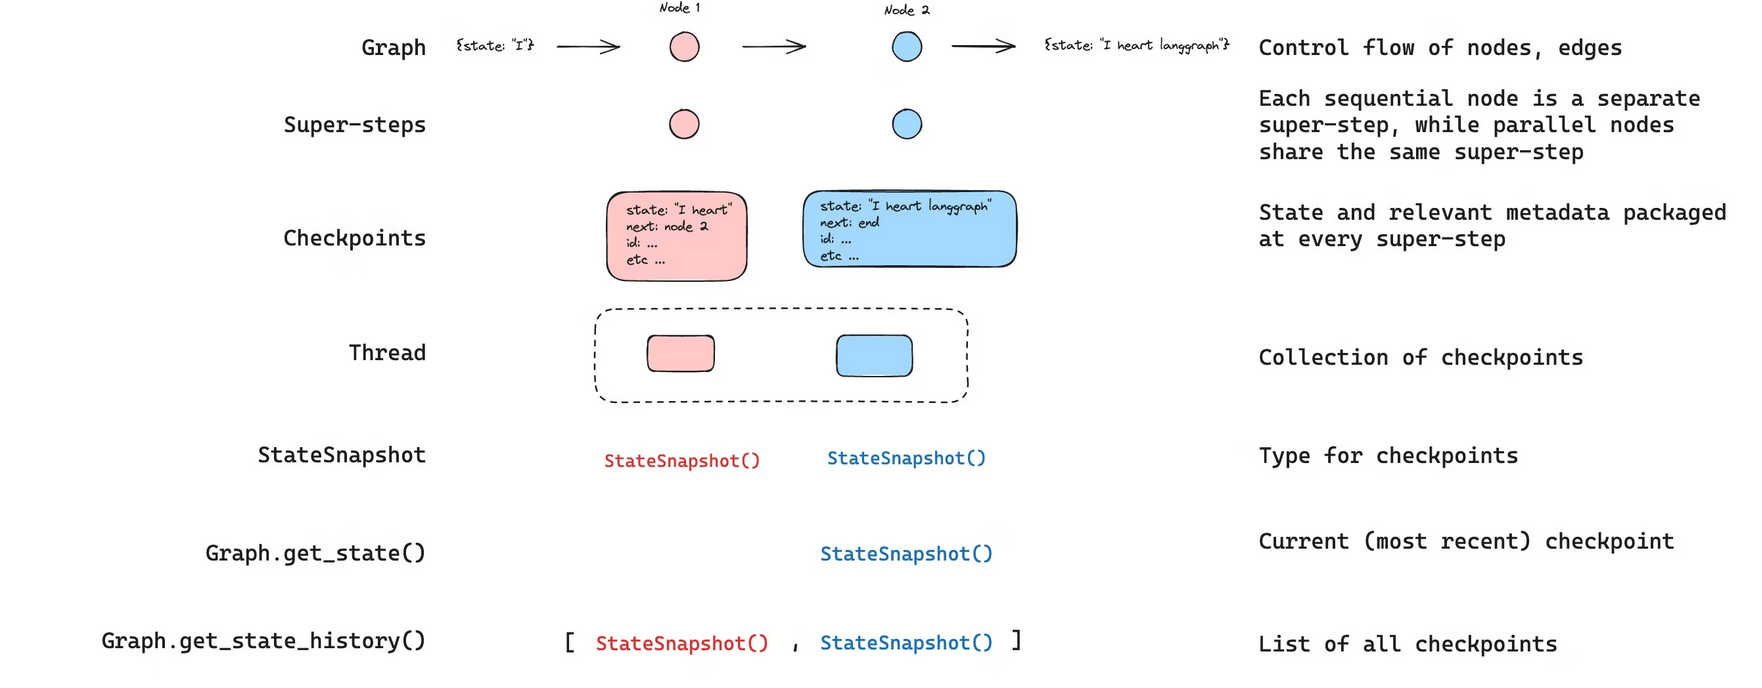

#### Replay

Replay allowed to re-execute a prior graph execution. If we invoke graph with a specific `thread_id` and a `checkpoint_id`, then the Graph will **replay all the BEFORE step (not execute)** then **execute all AFTER step** at the point we trigger.

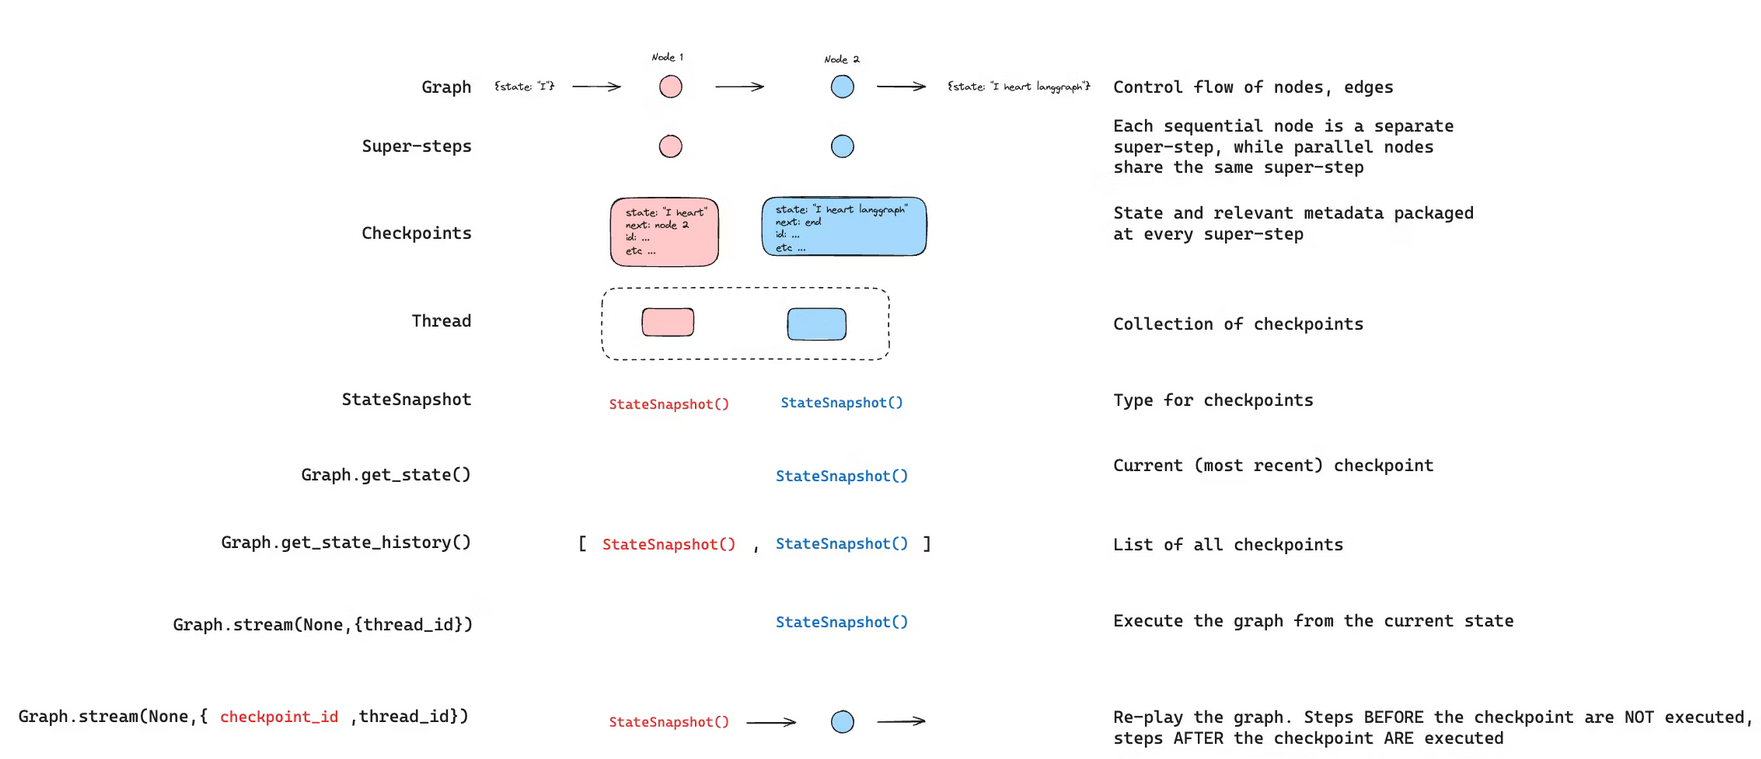

#### `graph.update_state`

We also can update the graph state. But:
- `config`: Should contain `thread_id` specifying which thread to update. When only the `thread_id` is passed, we update (or fork) the current state. Optionally, if we include checkpoint_id field, then we fork that selected checkpoint.
- `value`: Contain values that will be used to update the state. But the update method will based on the `reducer` and we can understand in 2 different way:
    - Overwrite: If there's no `reducer`
    - Adapt: Follow the `reducer` logic

Example:

```python
from typing import Annotated
from typing_extensions import TypedDict
from operator import add

class State(TypedDict):
    foo: int
    bar: Annotated[list[str], add]

Assume that the current state of the graph can be:

```
{"foo": 1, "bar": ["a"]}
```

Then update with:

```python
graph.update_state(config, {"foo": 2, "bar": ["b"]})

=> Final output: ```{"foo": 2, "bar": ["a", "b"]}```

- `as_node`: If this provide, the change will be applied as if it came from node being set. If `as_node` is not provided, it will be set to the last node that updated the state, if not ambiguous.

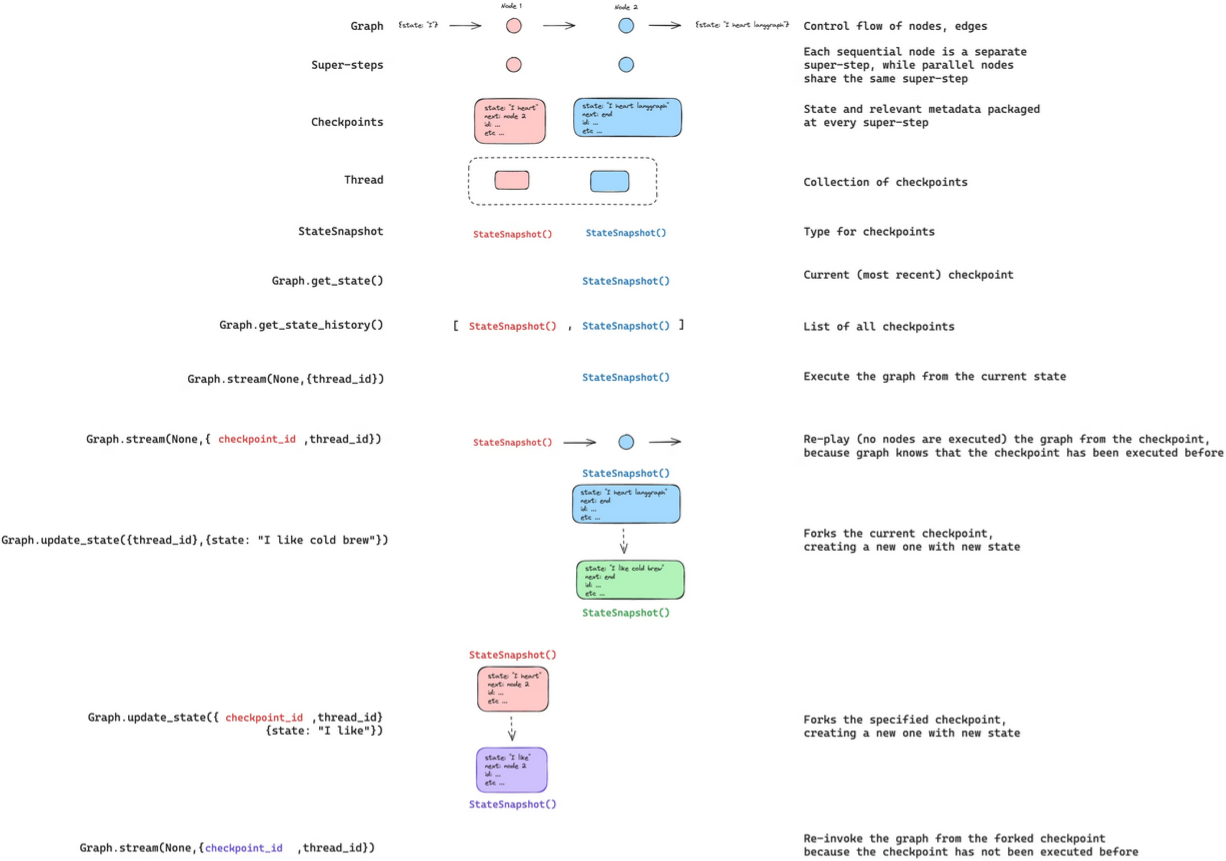